In [1]:
# Basic libraries
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Image processing
import cv2
from PIL import Image

# Feature extraction
from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

# Deep Learning
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

import warnings
warnings.filterwarnings("ignore")

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## Task 1: Data Acquisition and Exploration 

In [6]:
# ============================================================
# DATASET PATH
# ============================================================

DATASET_PATH = "/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia"

print("Dataset contents:")
print(os.listdir(DATASET_PATH))

Dataset contents:
['chest_xray']


In [7]:
# ============================================================
# CHEST X-RAY DATASET PATH
# ============================================================

CHEST_XRAY_PATH = os.path.join(
    DATASET_PATH,
    "chest_xray"
)

print("Chest X-Ray folders:")
print(os.listdir(CHEST_XRAY_PATH))

Chest X-Ray folders:
['chest_xray', '__MACOSX', 'val', 'test', 'train']


In [8]:
# ============================================================
# CHECK DATASET STRUCTURE
# ============================================================

for folder in ["train", "test", "val"]:
    
    folder_path = os.path.join(
        CHEST_XRAY_PATH,
        folder
    )
    
    print(f"\n{folder.upper()}")
    
    for class_name in ["NORMAL", "PNEUMONIA"]:
        
        class_path = os.path.join(
            folder_path,
            class_name
        )
        
        if os.path.exists(class_path):
            count = len([
                f for f in os.listdir(class_path)
                if f.lower().endswith(
                    (".jpg", ".jpeg", ".png")
                )
            ])
            
            print(f"{class_name}: {count}")


TRAIN
NORMAL: 1341
PNEUMONIA: 3875

TEST
NORMAL: 234
PNEUMONIA: 390

VAL
NORMAL: 8
PNEUMONIA: 8


In [9]:
# ============================================================
# COLLECT ALL IMAGES
# ============================================================

image_paths = []
labels = []

image_extensions = (
    ".jpg",
    ".jpeg",
    ".png"
)

for split in ["train", "test", "val"]:
    
    split_path = os.path.join(
        CHEST_XRAY_PATH,
        split
    )
    
    for class_name in ["NORMAL", "PNEUMONIA"]:
        
        class_path = os.path.join(
            split_path,
            class_name
        )
        
        if not os.path.exists(class_path):
            continue
        
        for filename in os.listdir(class_path):
            
            if filename.lower().endswith(
                image_extensions
            ):
                
                image_paths.append(
                    os.path.join(
                        class_path,
                        filename
                    )
                )
                
                # NORMAL = 0
                # PNEUMONIA = 1
                labels.append(
                    0 if class_name == "NORMAL" else 1
                )

print("Total images:", len(image_paths))
print("Normal images:", labels.count(0))
print("Pneumonia images:", labels.count(1))

Total images: 5856
Normal images: 1583
Pneumonia images: 4273


In [10]:
# ============================================================
# CREATE DATAFRAME
# ============================================================

df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

df["class_name"] = df["label"].map({
    0: "NORMAL",
    1: "PNEUMONIA"
})

print(df.head())
print("\nDataset shape:", df.shape)

                                          image_path  label class_name
0  /kaggle/input/datasets/paultimothymooney/chest...      0     NORMAL
1  /kaggle/input/datasets/paultimothymooney/chest...      0     NORMAL
2  /kaggle/input/datasets/paultimothymooney/chest...      0     NORMAL
3  /kaggle/input/datasets/paultimothymooney/chest...      0     NORMAL
4  /kaggle/input/datasets/paultimothymooney/chest...      0     NORMAL

Dataset shape: (5856, 3)


CLASS DISTRIBUTION
class_name
PNEUMONIA    4273
NORMAL       1583
Name: count, dtype: int64

Total images: 5856


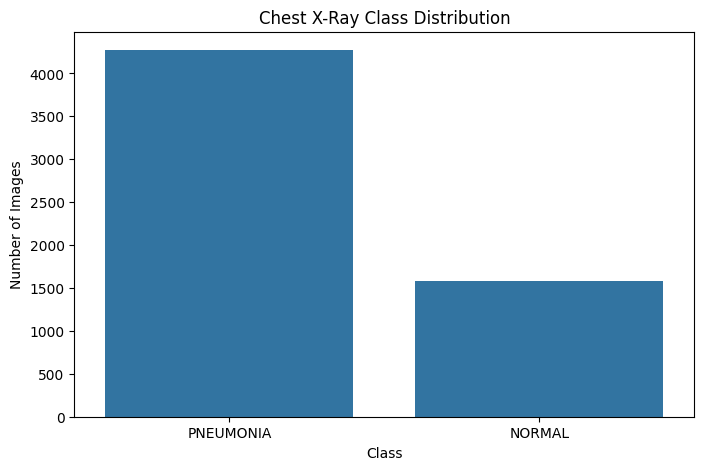

In [11]:
# ============================================================
# CLASS DISTRIBUTION
# ============================================================

class_counts = df["class_name"].value_counts()

print("CLASS DISTRIBUTION")
print("==================")
print(class_counts)

print("\nTotal images:", len(df))

plt.figure(figsize=(8, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Chest X-Ray Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.show()

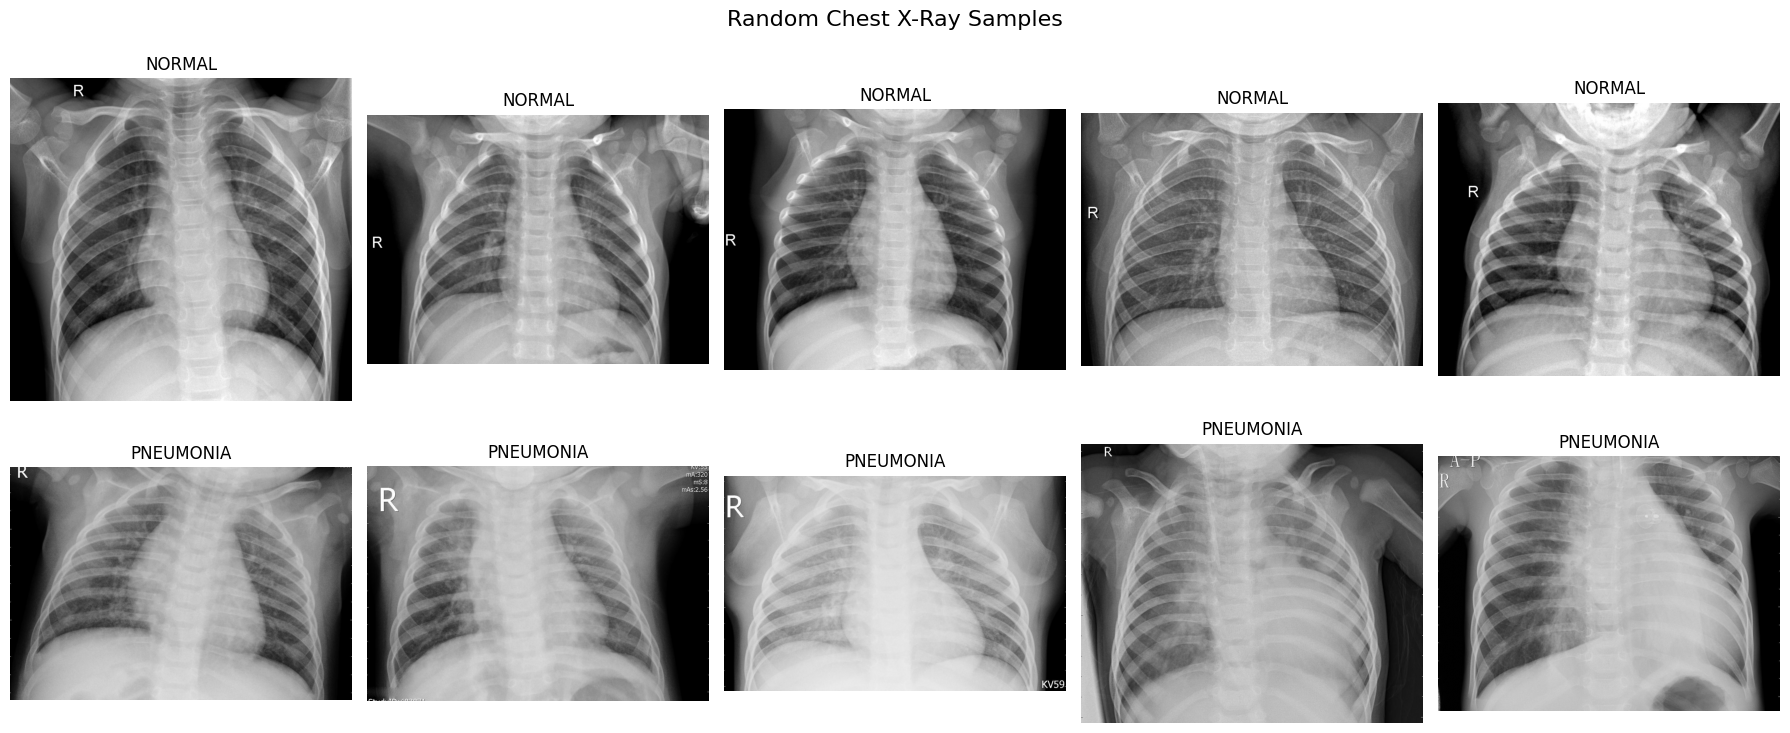

In [12]:
# ============================================================
# DISPLAY RANDOM IMAGES
# ============================================================

fig, axes = plt.subplots(
    2,
    5,
    figsize=(18, 8)
)

for row, class_name in enumerate(
    ["NORMAL", "PNEUMONIA"]
):
    
    samples = df[
        df["class_name"] == class_name
    ].sample(
        n=5,
        random_state=42
    )
    
    for col, (_, sample) in enumerate(
        samples.iterrows()
    ):
        
        image = cv2.imread(
            sample["image_path"],
            cv2.IMREAD_GRAYSCALE
        )
        
        axes[row, col].imshow(
            image,
            cmap="gray"
        )
        
        axes[row, col].set_title(
            class_name
        )
        
        axes[row, col].axis("off")

plt.suptitle(
    "Random Chest X-Ray Samples",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [13]:
# ============================================================
# CHECK ORIGINAL IMAGE DIMENSIONS
# ============================================================

sizes = []

sample_paths = random.sample(
    image_paths,
    min(500, len(image_paths))
)

for path in sample_paths:
    
    image = cv2.imread(path)
    
    if image is not None:
        
        height, width = image.shape[:2]
        
        sizes.append(
            (width, height)
        )

size_df = pd.DataFrame(
    sizes,
    columns=["Width", "Height"]
)

print(size_df.describe())

             Width       Height
count   500.000000   500.000000
mean   1320.394000   971.800000
std     347.640404   383.066009
min     446.000000   132.000000
25%    1072.000000   696.000000
50%    1264.000000   880.000000
75%    1552.000000  1180.000000
max    2518.000000  2376.000000


In [14]:
# ============================================================
# TRAIN / VALIDATION / TEST SPLIT
# ============================================================

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("TRAINING SET")
print("============")
print("Images:", len(train_df))
print("Percentage:", len(train_df) / len(df) * 100)

print("\nVALIDATION SET")
print("==============")
print("Images:", len(val_df))
print("Percentage:", len(val_df) / len(df) * 100)

print("\nTESTING SET")
print("===========")
print("Images:", len(test_df))
print("Percentage:", len(test_df) / len(df) * 100)

TRAINING SET
Images: 4099
Percentage: 69.99658469945356

VALIDATION SET
Images: 878
Percentage: 14.993169398907105

TESTING SET
Images: 879
Percentage: 15.010245901639344


In [15]:
# ============================================================
# CLASS DISTRIBUTION AFTER SPLIT
# ============================================================

print("Training:")
print(train_df["class_name"].value_counts())

print("\nValidation:")
print(val_df["class_name"].value_counts())

print("\nTesting:")
print(test_df["class_name"].value_counts())

Training:
class_name
PNEUMONIA    2991
NORMAL       1108
Name: count, dtype: int64

Validation:
class_name
PNEUMONIA    641
NORMAL       237
Name: count, dtype: int64

Testing:
class_name
PNEUMONIA    641
NORMAL       238
Name: count, dtype: int64


## Task 2: Data Preprocessing 

In [16]:
# ============================================================
# IMAGE PREPROCESSING
# ============================================================

IMG_SIZE = 128

def preprocess_image(path):
    
    image = cv2.imread(
        path,
        cv2.IMREAD_GRAYSCALE
    )
    
    if image is None:
        return None
    
    # Resize to 128 x 128
    image = cv2.resize(
        image,
        (IMG_SIZE, IMG_SIZE)
    )
    
    # Normalize pixel values
    image = image.astype(
        np.float32
    ) / 255.0
    
    # Add channel dimension
    image = np.expand_dims(
        image,
        axis=-1
    )
    
    return image

In [17]:
# ============================================================
# CREATE NUMPY DATASETS
# ============================================================

def create_dataset(dataframe):
    
    X = []
    y = []
    
    for _, row in dataframe.iterrows():
        
        image = preprocess_image(
            row["image_path"]
        )
        
        if image is not None:
            
            X.append(image)
            y.append(row["label"])
    
    return (
        np.array(X),
        np.array(y)
    )


X_train, y_train = create_dataset(
    train_df
)

X_val, y_val = create_dataset(
    val_df
)

X_test, y_test = create_dataset(
    test_df
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (4099, 128, 128, 1)
y_train: (4099,)
X_val: (878, 128, 128, 1)
y_val: (878,)
X_test: (879, 128, 128, 1)
y_test: (879,)


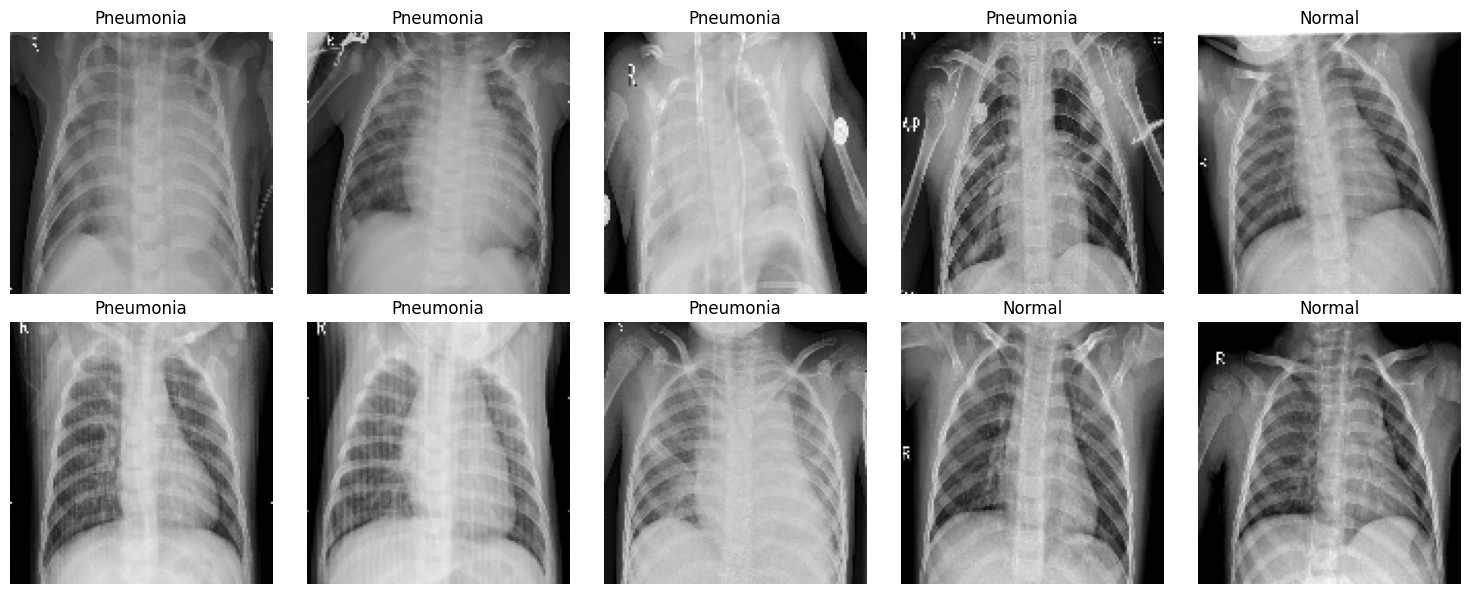

In [18]:
# ============================================================
# VISUALIZE PREPROCESSED IMAGES
# ============================================================

plt.figure(figsize=(15, 6))

for i in range(10):
    
    plt.subplot(2, 5, i + 1)
    
    plt.imshow(
        X_train[i].squeeze(),
        cmap="gray"
    )
    
    title = (
        "Pneumonia"
        if y_train[i] == 1
        else "Normal"
    )
    
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:
# ============================================================
# HOG FEATURE EXTRACTION
# ============================================================

def extract_hog_features(image):
    
    image = image.squeeze()
    
    features = hog(
        image,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )
    
    return features


hog_features = np.array([
    extract_hog_features(img)
    for img in X_train
])

print(
    "HOG feature shape:",
    hog_features.shape
)

HOG feature shape: (4099, 1764)


In [20]:
# ============================================================
# LBP FEATURE EXTRACTION
# ============================================================

def extract_lbp_features(image):
    
    image = (
        image.squeeze() * 255
    ).astype(np.uint8)
    
    radius = 1
    n_points = 8 * radius
    
    lbp = local_binary_pattern(
        image,
        n_points,
        radius,
        method="uniform"
    )
    
    n_bins = n_points + 2
    
    histogram, _ = np.histogram(
        lbp.ravel(),
        bins=n_bins,
        range=(0, n_bins),
        density=True
    )
    
    return histogram


lbp_features = np.array([
    extract_lbp_features(img)
    for img in X_train
])

print(
    "LBP feature shape:",
    lbp_features.shape
)

LBP feature shape: (4099, 10)


In [21]:
# ============================================================
# GLCM FEATURE EXTRACTION
# ============================================================

def extract_glcm_features(image):
    
    image = (
        image.squeeze() * 255
    ).astype(np.uint8)
    
    # Reduce intensity levels
    image = image // 32
    
    glcm = graycomatrix(
        image,
        distances=[1],
        angles=[
            0,
            np.pi / 4,
            np.pi / 2,
            3 * np.pi / 4
        ],
        levels=8,
        symmetric=True,
        normed=True
    )
    
    features = []
    
    properties = [
        "contrast",
        "dissimilarity",
        "homogeneity",
        "energy",
        "correlation"
    ]
    
    for prop in properties:
        
        values = graycoprops(
            glcm,
            prop
        )
        
        features.extend(
            values.flatten()
        )
    
    return np.array(features)


glcm_features = np.array([
    extract_glcm_features(img)
    for img in X_train
])

print(
    "GLCM feature shape:",
    glcm_features.shape
)

GLCM feature shape: (4099, 20)


In [22]:
# ============================================================
# COMBINE FEATURES
# ============================================================

combined_features = np.concatenate(
    [
        hog_features,
        lbp_features,
        glcm_features
    ],
    axis=1
)

print(
    "Combined feature vector shape:",
    combined_features.shape
)

Combined feature vector shape: (4099, 1794)


In [23]:
# ============================================================
# CNN MODEL
# ============================================================

def build_cnn(
    learning_rate=0.001,
    dropout_rate=0.5
):
    
    model = models.Sequential([
        
        layers.Input(
            shape=(128, 128, 1)
        ),
        
        # Convolution Block 1
        layers.Conv2D(
            32,
            (3, 3),
            activation="relu",
            padding="same"
        ),
        
        layers.MaxPooling2D(
            (2, 2)
        ),
        
        # Convolution Block 2
        layers.Conv2D(
            64,
            (3, 3),
            activation="relu",
            padding="same"
        ),
        
        layers.MaxPooling2D(
            (2, 2)
        ),
        
        # Convolution Block 3
        layers.Conv2D(
            128,
            (3, 3),
            activation="relu",
            padding="same"
        ),
        
        layers.MaxPooling2D(
            (2, 2)
        ),
        
        layers.Dropout(0.3),
        
        # Fully Connected Layer
        layers.Flatten(),
        
        layers.Dense(
            128,
            activation="relu"
        ),
        
        layers.Dropout(
            dropout_rate
        ),
        
        # Output
        layers.Dense(
            1,
            activation="sigmoid"
        )
    ])
    
    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.Precision(
                name="precision"
            ),
            tf.keras.metrics.Recall(
                name="recall"
            ),
            tf.keras.metrics.AUC(
                name="auc"
            )
        ]
    )
    
    return model

## Task 3: Model Training and Basic Evaluation 

In [24]:
# ============================================================
# CREATE BASELINE MODEL
# ============================================================

model = build_cnn(
    learning_rate=0.001,
    dropout_rate=0.5
)

model.summary()

I0000 00:00:1790852736.980212      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790852736.983096      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,287,233 (16.35 MB)

 Trainable params: 4,287,233 (16.35 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
from sklearn.utils.class_weight import compute_class_weight

In [27]:
# ============================================================
# CLASS WEIGHTS
# ============================================================

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(
    zip(classes, weights)
)

print("Class weights:")
print(class_weights)

Class weights:
{np.int64(0): np.float64(1.8497292418772564), np.int64(1): np.float64(0.6852223336676697)}


In [28]:
# ============================================================
# TRAIN CNN
# ============================================================

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(
        X_val,
        y_val
    ),
    epochs=20,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[
        early_stopping,
        reduce_lr
    ],
    verbose=1
)

Epoch 1/20
  7/129 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.5688 - auc: 0.6048 - loss: 0.6921 - precision: 0.7694 - recall: 0.5762

I0000 00:00:1790852849.615857     216 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


129/129 ━━━━━━━━━━━━━━━━━━━━ 16s 63ms/step - accuracy: 0.8558 - auc: 0.9347 - loss: 0.3289 - precision: 0.9441 - recall: 0.8529 - val_accuracy: 0.8554 - val_auc: 0.9869 - val_loss: 0.3293 - val_precision: 0.9942 - val_recall: 0.8066 - learning_rate: 0.0010
Epoch 2/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.9253 - auc: 0.9757 - loss: 0.1976 - precision: 0.9735 - recall: 0.9228 - val_accuracy: 0.9339 - val_auc: 0.9854 - val_loss: 0.1538 - val_precision: 0.9740 - val_recall: 0.9345 - learning_rate: 0.0010
Epoch 3/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9334 - auc: 0.9790 - loss: 0.1818 - precision: 0.9732 - recall: 0.9345 - val_accuracy: 0.9385 - val_auc: 0.9901 - val_loss: 0.1399 - val_precision: 0.9804 - val_recall: 0.9345 - learning_rate: 0.0010
Epoch 4/20
129/129 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9456 - auc: 0.9865 - loss: 0.1458 - precision: 0.9806 - recall: 0.9442 - val_accuracy: 0.9476 - val_auc: 0.9900 - val_loss: 0.1264 - val_preci

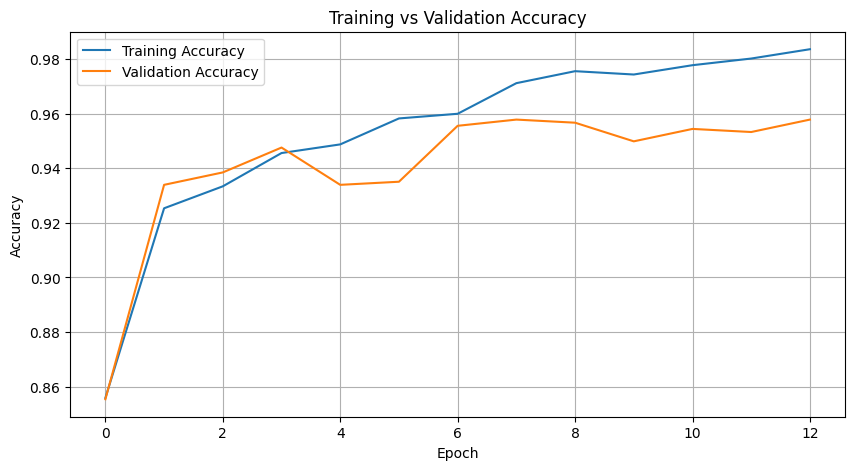

In [29]:
# ============================================================
# TRAINING / VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title(
    "Training vs Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.show()

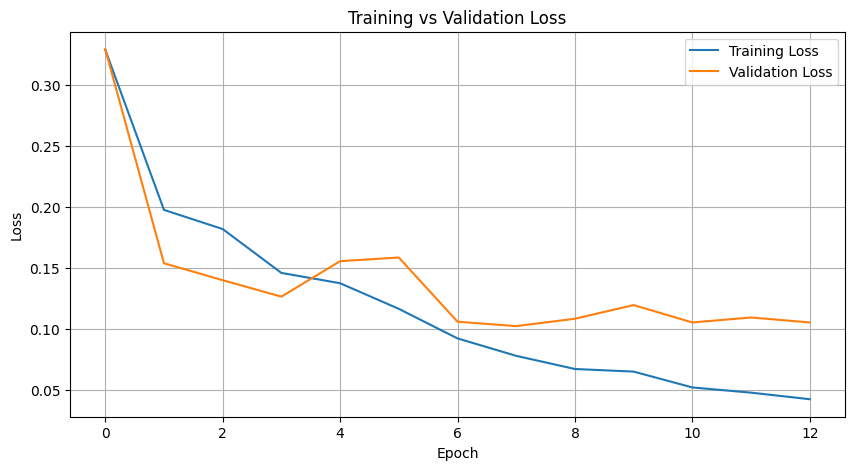

In [30]:
# ============================================================
# TRAINING / VALIDATION LOSS
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title(
    "Training vs Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.show()

In [31]:
# ============================================================
# TEST SET PREDICTIONS
# ============================================================

y_prob = model.predict(
    X_test,
    verbose=1
).ravel()

y_pred = (
    y_prob >= 0.5
).astype(int)

print("Prediction completed.")

28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step
Prediction completed.


In [32]:
# ============================================================
# EVALUATION METRICS
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

auroc = roc_auc_score(
    y_test,
    y_prob
)

print("===================================")
print("       CNN EVALUATION RESULTS")
print("===================================")

print(
    f"Accuracy  : {accuracy:.4f}"
)

print(
    f"Precision : {precision:.4f}"
)

print(
    f"Recall    : {recall:.4f}"
)

print(
    f"F1-Score  : {f1:.4f}"
)

print(
    f"AUROC     : {auroc:.4f}"
)

       CNN EVALUATION RESULTS
Accuracy  : 0.9590
Precision : 0.9794
Recall    : 0.9641
F1-Score  : 0.9717
AUROC     : 0.9905


In [33]:
# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Normal",
            "Pneumonia"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Normal       0.91      0.95      0.93       238
   Pneumonia       0.98      0.96      0.97       641

    accuracy                           0.96       879
   macro avg       0.94      0.95      0.95       879
weighted avg       0.96      0.96      0.96       879



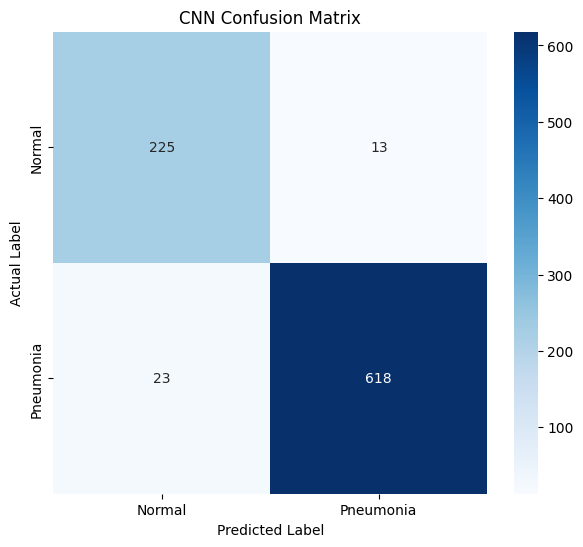

In [34]:
# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Normal",
        "Pneumonia"
    ],
    yticklabels=[
        "Normal",
        "Pneumonia"
    ]
)

plt.title(
    "CNN Confusion Matrix"
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "Actual Label"
)

plt.show()

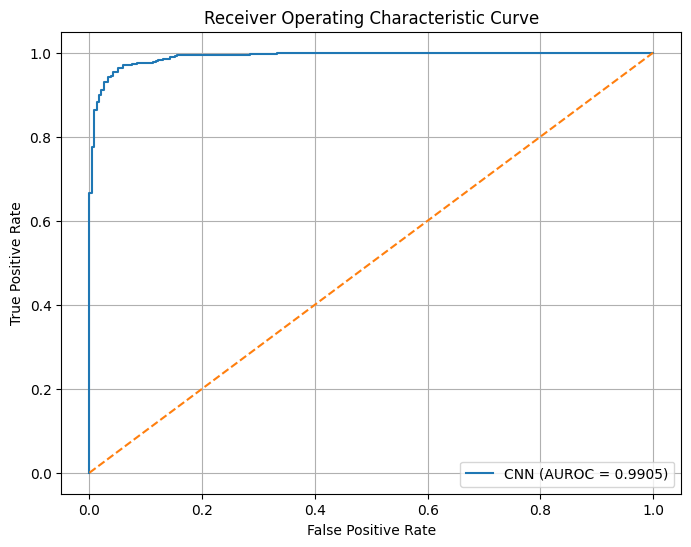

In [35]:
# ============================================================
# ROC CURVE
# ============================================================

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"CNN (AUROC = {auroc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Receiver Operating Characteristic Curve"
)

plt.legend()

plt.grid(True)

plt.show()

Number of misclassified images: 36


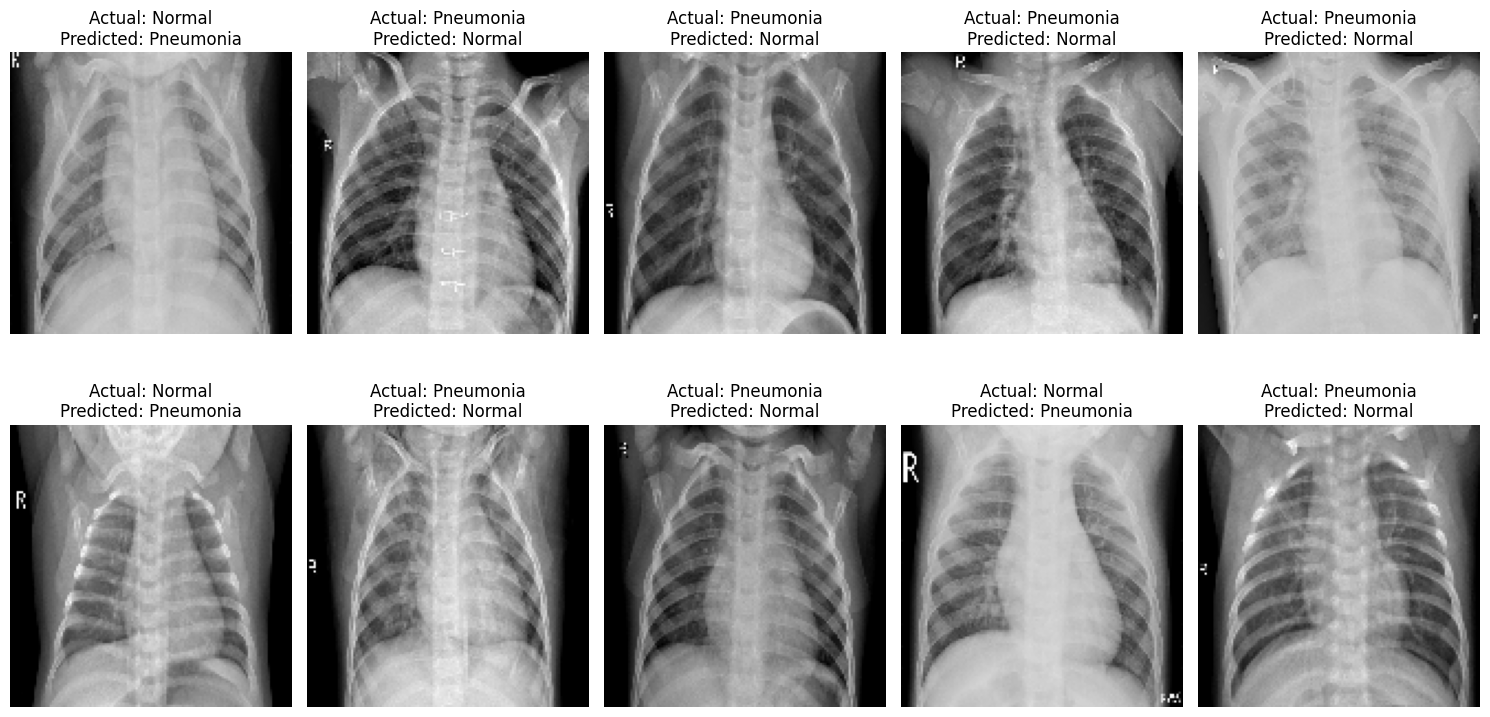

In [36]:
# ============================================================
# MISCLASSIFIED IMAGES
# ============================================================

incorrect_indices = np.where(
    y_test != y_pred
)[0]

print(
    "Number of misclassified images:",
    len(incorrect_indices)
)

num_images = min(
    10,
    len(incorrect_indices)
)

plt.figure(figsize=(15, 8))

for i in range(num_images):
    
    idx = incorrect_indices[i]
    
    plt.subplot(
        2,
        5,
        i + 1
    )
    
    plt.imshow(
        X_test[idx].squeeze(),
        cmap="gray"
    )
    
    actual = (
        "Pneumonia"
        if y_test[idx] == 1
        else "Normal"
    )
    
    predicted = (
        "Pneumonia"
        if y_pred[idx] == 1
        else "Normal"
    )
    
    plt.title(
        f"Actual: {actual}\n"
        f"Predicted: {predicted}"
    )
    
    plt.axis("off")

plt.tight_layout()
plt.show()

In [37]:
# ============================================================
# HYPERPARAMETER TUNING
# ============================================================

learning_rates = [
    0.001,
    0.0005,
    0.0001
]

tuning_results = []

for lr in learning_rates:
    
    print(
        f"\nTraining with learning rate: {lr}"
    )
    
    temp_model = build_cnn(
        learning_rate=lr,
        dropout_rate=0.5
    )
    
    temp_history = temp_model.fit(
        X_train,
        y_train,
        validation_data=(
            X_val,
            y_val
        ),
        epochs=5,
        batch_size=32,
        class_weight=class_weights,
        verbose=0
    )
    
    best_val_accuracy = max(
        temp_history.history[
            "val_accuracy"
        ]
    )
    
    tuning_results.append({
        "Learning Rate": lr,
        "Best Validation Accuracy":
            best_val_accuracy
    })

tuning_df = pd.DataFrame(
    tuning_results
)

tuning_df


Training with learning rate: 0.001

Training with learning rate: 0.0005

Training with learning rate: 0.0001


,Learning Rate,Best Validation Accuracy
0,0.0010,0.947608
1,0.0005,0.952164
2,0.0001,0.945330


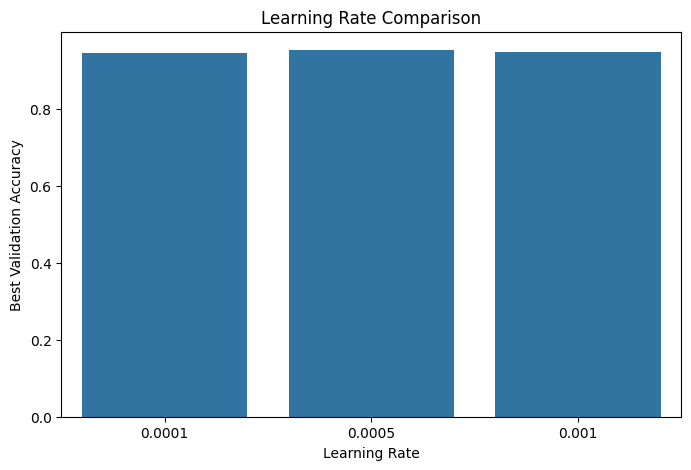

In [38]:
# ============================================================
# HYPERPARAMETER RESULTS
# ============================================================

plt.figure(figsize=(8, 5))

sns.barplot(
    data=tuning_df,
    x="Learning Rate",
    y="Best Validation Accuracy"
)

plt.title(
    "Learning Rate Comparison"
)

plt.ylabel(
    "Best Validation Accuracy"
)

plt.show()

In [39]:
# ============================================================
# FINAL RESULTS TABLE
# ============================================================

results = pd.DataFrame({
    
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "AUROC"
    ],
    
    "CNN": [
        accuracy,
        precision,
        recall,
        f1,
        auroc
    ]
})

results["CNN"] = results[
    "CNN"
].round(4)

print(results)

      Metric     CNN
0   Accuracy  0.9590
1  Precision  0.9794
2     Recall  0.9641
3   F1-Score  0.9717
4      AUROC  0.9905


In [40]:
# ============================================================
# SAVE MODEL
# ============================================================

model.save(
    "/kaggle/working/chest_xray_cnn.h5"
)

print(
    "Model saved at:"
)

print(
    "/kaggle/working/chest_xray_cnn.h5"
)

Model saved at:
/kaggle/working/chest_xray_cnn.h5


In [41]:
# ============================================================
# SAVE RESULTS
# ============================================================

results.to_csv(
    "/kaggle/working/cnn_results.csv",
    index=False
)

tuning_df.to_csv(
    "/kaggle/working/hyperparameter_results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!
